In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model evaluation
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving house_train.csv to house_train.csv
Saving titanic_train.csv to titanic_train.csv


In [7]:
# Load Titanic dataset
titanic_df = pd.read_csv("titanic_train.csv")

# Load House Prices dataset
house_df = pd.read_csv("house_train.csv")

print("Titanic Dataset Shape:", titanic_df.shape)
print("House Dataset Shape:", house_df.shape)

print("\nTitanic Dataset:")
display(titanic_df.head())

print("\nHouse Prices Dataset:")
display(house_df.head())

Titanic Dataset Shape: (891, 12)
House Dataset Shape: (1460, 81)

Titanic Dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



House Prices Dataset:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [8]:
# Display first 5 records
display(house_df.head())

# Dataset information
print("Dataset Information:")
house_df.info()

# Statistical summary
print("\nStatistical Summary:")
display(house_df.describe())

# Check missing values
print("\nMissing Values:")
print(house_df.isnull().sum().sort_values(ascending=False).head(15))

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



Missing Values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
dtype: int64


In [9]:
# Separate input features and target
X_house = house_df.drop(columns=["SalePrice", "Id"], errors="ignore")
y_house = house_df["SalePrice"]

# Identify numerical and categorical columns
numeric_features = X_house.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_house.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 36
Categorical Features: 43


In [10]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Data preprocessing setup completed!")

Data preprocessing setup completed!


In [11]:
X_train_house, X_test_house, y_train_house, y_test_house = train_test_split(
    X_house,
    y_house,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train_house))
print("Testing records:", len(X_test_house))

Training records: 1168
Testing records: 292


In [13]:
# Predict house prices
house_predictions = house_model.predict(X_test_house)

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual Price": y_test_house.values,
    "Predicted Price": house_predictions.round(2)
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,154500,157609.21
1,325000,348503.30
2,115000,86473.72
3,159000,174161.64
4,315500,316991.41
5,75500,66791.52
6,311500,236155.12
7,146000,146009.09
8,84500,57574.42
9,135500,154052.47


In [14]:
# Calculate Mean Squared Error
mse = mean_squared_error(y_test_house, house_predictions)

# Calculate R2 Score
r2 = r2_score(y_test_house, house_predictions)

print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 4))

Mean Squared Error: 868709192.88
R2 Score: 0.8867


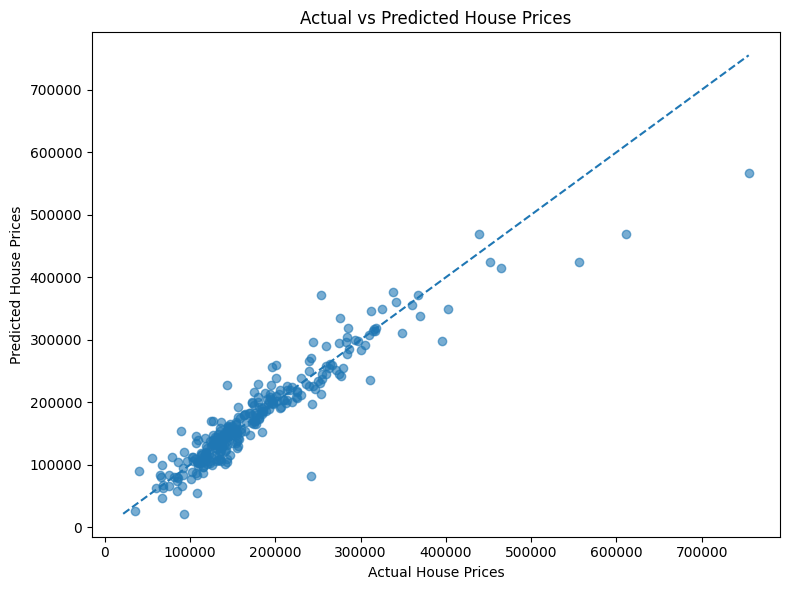

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_house,
    house_predictions,
    alpha=0.6
)

# Reference line for perfect predictions
minimum = min(y_test_house.min(), house_predictions.min())
maximum = max(y_test_house.max(), house_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.tight_layout()
plt.savefig("house_price_prediction.png", dpi=300)
plt.show()

In [16]:
print("HOUSE PRICE PREDICTION - FINAL RESULTS")

print("Model: Linear Regression")
print("Total training records:", len(X_train_house))
print("Total testing records:", len(X_test_house))

print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 4))

print("\nProject completed successfully!")

HOUSE PRICE PREDICTION - FINAL RESULTS
Model: Linear Regression
Total training records: 1168
Total testing records: 292
Mean Squared Error: 868709192.88
R2 Score: 0.8867

Project completed successfully!


In [17]:
# Save comparison results
comparison.to_csv(
    "house_price_predictions.csv",
    index=False
)

# Save the cleaned housing dataset
house_df.to_csv(
    "house_prices_dataset.csv",
    index=False
)

print("Project files saved successfully!")

Project files saved successfully!


In [18]:
# Display first 5 rows
display(titanic_df.head())

# Dataset information
print("Dataset Information:")
titanic_df.info()

# Check survival distribution
print("\nSurvival Count:")
print(titanic_df["Survived"].value_counts())

# Check missing values
print("\nMissing Values:")
print(titanic_df.isnull().sum())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Par

In [19]:
# Select useful features
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X_titanic = titanic_df[features]
y_titanic = titanic_df["Survived"]

print("Features:")
display(X_titanic.head())

print("\nTarget:")
print(y_titanic.head())

Features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S



Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [20]:
# Identify numerical and categorical features
titanic_numeric = X_titanic.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

titanic_categorical = X_titanic.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
titanic_num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
titanic_cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
titanic_preprocessor = ColumnTransformer(
    transformers=[
        ("num", titanic_num_transformer, titanic_numeric),
        ("cat", titanic_cat_transformer, titanic_categorical)
    ]
)

print("Titanic preprocessing completed!")

Titanic preprocessing completed!


In [21]:
X_train_titanic, X_test_titanic, y_train_titanic, y_test_titanic = train_test_split(
    X_titanic,
    y_titanic,
    test_size=0.2,
    random_state=42,
    stratify=y_titanic
)

print("Training records:", len(X_train_titanic))
print("Testing records:", len(X_test_titanic))

Training records: 712
Testing records: 179


In [22]:
# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", titanic_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(
    X_train_titanic,
    y_train_titanic
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [23]:
# Predict passenger survival
titanic_predictions = logistic_model.predict(X_test_titanic)

# Compare actual and predicted results
survival_comparison = pd.DataFrame({
    "Actual Survival": y_test_titanic.values,
    "Predicted Survival": titanic_predictions
})

display(survival_comparison.head(10))

,Actual Survival,Predicted Survival
0,0,0
1,0,0
2,1,0
3,0,0
4,1,1
5,1,0
6,1,1
7,0,0
8,0,0
9,0,0


In [24]:
accuracy = accuracy_score(
    y_test_titanic,
    titanic_predictions
)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 80.45 %


In [25]:
# Train Logistic Regression model
practice_logistic_model = Pipeline(steps=[
    ("preprocessor", titanic_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

practice_logistic_model.fit(
    X_train_titanic,
    y_train_titanic
)

# Make predictions
practice_predictions = practice_logistic_model.predict(
    X_test_titanic
)

print("Practice Logistic Regression completed!")

print("Accuracy:",
      round(accuracy_score(
          y_test_titanic,
          practice_predictions
      ) * 100, 2), "%")

Practice Logistic Regression completed!
Accuracy: 80.45 %


Confusion Matrix:
[[98 12]
 [23 46]]


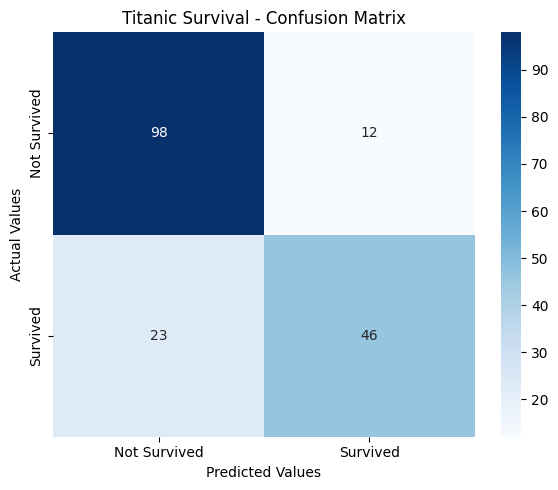

Accuracy Score: 0.8045
Accuracy Percentage: 80.45 %


In [26]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test_titanic,
    practice_predictions
)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Titanic Survival - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.tight_layout()
plt.savefig("titanic_confusion_matrix.png", dpi=300)
plt.show()

# Calculate accuracy
accuracy = accuracy_score(
    y_test_titanic,
    practice_predictions
)

print("Accuracy Score:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

In [27]:
# Create Decision Tree model
decision_tree_model = Pipeline(steps=[
    ("preprocessor", titanic_preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train model
decision_tree_model.fit(
    X_train_titanic,
    y_train_titanic
)

# Make predictions
dt_predictions = decision_tree_model.predict(
    X_test_titanic
)

# Calculate accuracy
dt_accuracy = accuracy_score(
    y_test_titanic,
    dt_predictions
)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 81.56 %


In [28]:
# Create KNN model
knn_model = Pipeline(steps=[
    ("preprocessor", titanic_preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train model
knn_model.fit(
    X_train_titanic,
    y_train_titanic
)

# Make predictions
knn_predictions = knn_model.predict(
    X_test_titanic
)

# Calculate accuracy
knn_accuracy = accuracy_score(
    y_test_titanic,
    knn_predictions
)

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 81.56 %


,Model,Accuracy (%)
0,Decision Tree,81.564246
1,K-Nearest Neighbors,81.564246


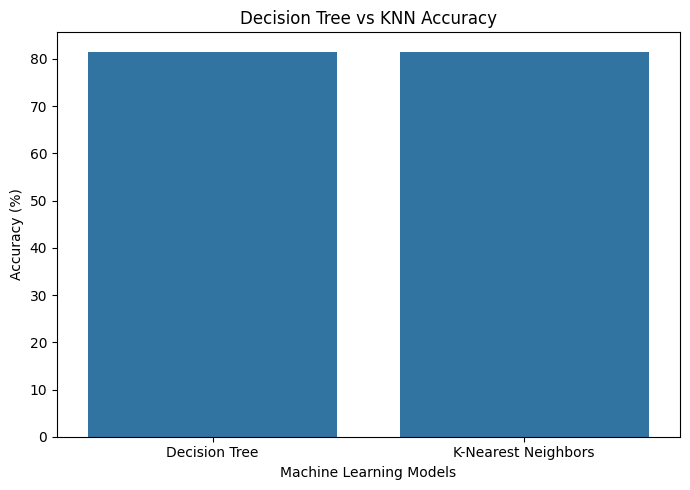

In [29]:
# Create comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "K-Nearest Neighbors"
    ],
    "Accuracy (%)": [
        dt_accuracy * 100,
        knn_accuracy * 100
    ]
})

display(model_comparison)

# Plot comparison
plt.figure(figsize=(7, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Decision Tree vs KNN Accuracy")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Models")

plt.tight_layout()
plt.savefig("model_accuracy_comparison.png", dpi=300)
plt.show()

In [30]:
if dt_accuracy > knn_accuracy:
    print("Decision Tree performed better.")
elif knn_accuracy > dt_accuracy:
    print("KNN performed better.")
else:
    print("Both models have equal accuracy.")

Both models have equal accuracy.


In [31]:
# Different maximum depths
depth_values = [1, 2, 3, 4, 5, 7, 10, None]

results = []

for depth in depth_values:

    # Create model
    tree_model = Pipeline(steps=[
        ("preprocessor", titanic_preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    # Train model
    tree_model.fit(
        X_train_titanic,
        y_train_titanic
    )

    # Training accuracy
    train_predictions = tree_model.predict(
        X_train_titanic
    )

    train_accuracy = accuracy_score(
        y_train_titanic,
        train_predictions
    )

    # Testing accuracy
    test_predictions = tree_model.predict(
        X_test_titanic
    )

    test_accuracy = accuracy_score(
        y_test_titanic,
        test_predictions
    )

    # Store results
    results.append({
        "Max Depth": str(depth),
        "Training Accuracy (%)": train_accuracy * 100,
        "Testing Accuracy (%)": test_accuracy * 100
    })

# Display results
depth_results = pd.DataFrame(results)

display(depth_results.round(2))

,Max Depth,Training Accuracy (%),Testing Accuracy (%)
0,1,78.93,77.65
1,2,80.48,75.98
2,3,83.29,79.33
3,4,84.13,79.33
4,5,86.52,76.54
5,7,89.19,81.56
6,10,93.96,80.45
7,None,98.31,81.56


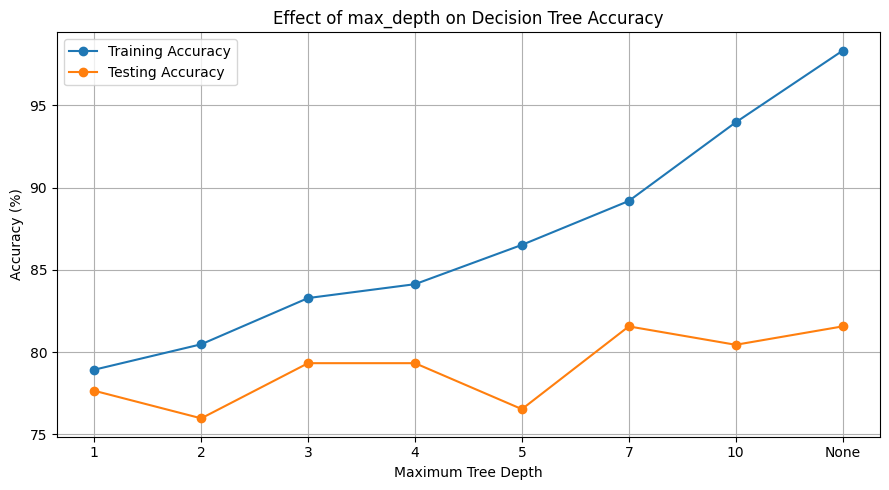

In [32]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_results["Max Depth"],
    depth_results["Training Accuracy (%)"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["Max Depth"],
    depth_results["Testing Accuracy (%)"],
    marker="o",
    label="Testing Accuracy"
)

plt.title("Effect of max_depth on Decision Tree Accuracy")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("decision_tree_depth_comparison.png", dpi=300)
plt.show()

In [33]:
best_row = depth_results.loc[
    depth_results["Testing Accuracy (%)"].idxmax()
]

print("Best Max Depth:", best_row["Max Depth"])

print(
    "Best Testing Accuracy:",
    round(best_row["Testing Accuracy (%)"], 2),
    "%"
)

Best Max Depth: 7
Best Testing Accuracy: 81.56 %
